# 作业3：多层感知机实战 —— 心脏病预测（MLP）

使用 PyTorch 手写 MLP（3 个隐藏层 + BatchNorm + Dropout）完成心脏病二分类。

运行说明：请将 `train.csv`、`test.csv`、`example_submission.csv` 与本文件放在同一目录（或修改下方读取路径）；需已安装 pandas、scikit-learn、torch、matplotlib。


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 中文字体配置：避免图标题/坐标轴中文显示为方框
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False   # 正常显示负号
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset


In [2]:
# ============================================
# 0. 固定随机种子，保证实验结果可复现
# ============================================
torch.manual_seed(42)
np.random.seed(42)


In [3]:
# ============================================
# 1. 加载数据（任务流程第1步）
# ============================================
train = pd.read_csv("train.csv")                 # 训练集：含标签 HeartDisease
test = pd.read_csv("test.csv")                   # 测试集：不含标签
sample = pd.read_csv("example_submission.csv")   # 提交格式示例

print("train:", train.shape, "| test:", test.shape)
print("提交示例列名：", list(sample.columns))


train: (818, 13) | test: (100, 12)
提交示例列名： ['id', 'HeartDisease']


In [4]:
# ============================================
# 2. EDA：结构、统计与分布（任务流程第1步）
# ============================================
print("\n=== 前5行数据 ===")
print(train.head())
print("\n=== 数据类型与非空 ===")
print(train.info())
print("\n=== 数值特征统计量 ===")
print(train.describe())

# 缺失值检查
print("\n=== 缺失值总数 ===")
print(train.isna().sum().sum())

# 类别特征分布
cat_cols = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]
for c in cat_cols:
    print(f"\n{c}:")
    print(train[c].value_counts())

# 标签分布（类别平衡情况）
print("\n=== HeartDisease 标签分布（比例） ===")
print(train["HeartDisease"].value_counts(normalize=True))



=== 前5行数据 ===
   id  Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  \
0   1   40   M           ATA        140          289          0     Normal   
1   2   49   F           NAP        160          180          0     Normal   
2   3   37   M           ATA        130          283          0         ST   
3   4   48   F           ASY        138          214          0     Normal   
4   5   54   M           NAP        150          195          0     Normal   

   MaxHR ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0    172              N      0.0       Up             0  
1    156              N      1.0     Flat             1  
2     98              N      0.0       Up             0  
3    108              Y      1.5     Flat             1  
4    122              N      0.0       Up             0  

=== 数据类型与非空 ===
<class 'pandas.DataFrame'>
RangeIndex: 818 entries, 0 to 817
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------ 

In [5]:
# ============================================
# 3. 预处理：One-Hot 编码 + Z-Score 标准化（任务流程第2步）
# ============================================
num_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak", "FastingBS"]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols),   # 数值特征：标准化
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),  # 类别特征：One-Hot 编码
])

X_train_raw = train.drop(columns=["id", "HeartDisease"])    # 特征（去掉 id 和标签）
y = train["HeartDisease"].values.astype(np.float32)          # 标签转 float（配合 BCEWithLogitsLoss）

X = preprocessor.fit_transform(X_train_raw)                  # 只在训练集上 fit
X_test = preprocessor.transform(test.drop(columns=["id"]))   # 测试集只 transform

feat_names = preprocessor.get_feature_names_out()
print(f"\n预处理后特征维度: {X.shape[1]}")
print("特征名:", list(feat_names))



预处理后特征维度: 20
特征名: ['num__Age', 'num__RestingBP', 'num__Cholesterol', 'num__MaxHR', 'num__Oldpeak', 'num__FastingBS', 'cat__Sex_F', 'cat__Sex_M', 'cat__ChestPainType_ASY', 'cat__ChestPainType_ATA', 'cat__ChestPainType_NAP', 'cat__ChestPainType_TA', 'cat__RestingECG_LVH', 'cat__RestingECG_Normal', 'cat__RestingECG_ST', 'cat__ExerciseAngina_N', 'cat__ExerciseAngina_Y', 'cat__ST_Slope_Down', 'cat__ST_Slope_Flat', 'cat__ST_Slope_Up']


In [6]:
# ============================================
# 4. 划分训练/验证集 + 构建 DataLoader（任务流程第2步）
# ============================================
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

# 转成 PyTorch Tensor，用 TensorDataset + DataLoader 支持小批量训练
train_ds = TensorDataset(torch.tensor(X_train, dtype=torch.float32),
                         torch.tensor(y_train, dtype=torch.float32))
val_ds = TensorDataset(torch.tensor(X_val, dtype=torch.float32),
                       torch.tensor(y_val, dtype=torch.float32))

BATCH_SIZE = 32
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)    # 训练：打乱
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)       # 验证：不打乱

print(f"训练样本: {len(train_ds)} | 验证样本: {len(val_ds)}")


训练样本: 695 | 验证样本: 123


In [7]:
# ============================================
# 5. 模型定义（任务流程第3步）
# ============================================
class HeartDiseaseClassifier(nn.Module):
    """用于心脏病二分类的 MLP。

    网络结构:
        Input (20) -> Linear(20, 64) -> BatchNorm1d(64) -> ReLU -> Dropout(0.3)
                   -> Linear(64, 32) -> BatchNorm1d(32) -> ReLU -> Dropout(0.3)
                   -> Linear(32, 16) -> BatchNorm1d(16) -> ReLU -> Dropout(0.3)
                   -> Linear(16, 1)   -> 输出 1 个 logit（配合 BCEWithLogitsLoss）
    """
    def __init__(self, input_size):
        super(HeartDiseaseClassifier, self).__init__()
        # 第一层：输入层 -> 64
        self.fc1 = nn.Linear(input_size, 64)
        self.bn1 = nn.BatchNorm1d(64)        # BatchNorm 加速收敛
        self.dropout1 = nn.Dropout(0.3)      # Dropout 缓解过拟合

        # 第二层：64 -> 32
        self.fc2 = nn.Linear(64, 32)
        self.bn2 = nn.BatchNorm1d(32)
        self.dropout2 = nn.Dropout(0.3)

        # 第三层：32 -> 16
        self.fc3 = nn.Linear(32, 16)
        self.bn3 = nn.BatchNorm1d(16)
        self.dropout3 = nn.Dropout(0.3)

        # 输出层：16 -> 1
        self.fc4 = nn.Linear(16, 1)

    def forward(self, x):
        """前向传播：每层依次经过 Linear -> BatchNorm -> ReLU -> Dropout"""
        # 第一层
        x = self.fc1(x)
        x = self.bn1(x)
        x = torch.relu(x)
        x = self.dropout1(x)

        # 第二层
        x = self.fc2(x)
        x = self.bn2(x)
        x = torch.relu(x)
        x = self.dropout2(x)

        # 第三层
        x = self.fc3(x)
        x = self.bn3(x)
        x = torch.relu(x)
        x = self.dropout3(x)

        # 输出层
        x = self.fc4(x)
        return x


In [8]:
# ============================================
# 6. 训练循环（任务流程第4步）
# ============================================
def train(model, train_loader, val_loader, epochs, lr):
    """
    完成模型训练：
      1) 每个 epoch 先遍历 train_loader 训练（前向-损失-反向-更新）；
      2) 再在 val_loader 上计算验证损失与准确率；
    返回 (train_losses, val_losses, val_accs) 三个记录列表，供画曲线。
    """
    # 损失函数：BCEWithLogitsLoss（二分类，模型输出 logit，内部自带 sigmoid）
    criterion = nn.BCEWithLogitsLoss()
    # 优化器：Adam
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_losses, val_losses, val_accs = [], [], []

    for epoch in range(epochs):
        # ===== 训练阶段 =====
        model.train()
        running_loss = 0.0
        for x_batch, y_batch in train_loader:
            # 前向传播：得到 logits
            logits = model(x_batch).squeeze()
            # 计算损失
            loss = criterion(logits, y_batch)
            # 反向传播
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * x_batch.size(0)

        # 平均训练损失
        avg_train_loss = running_loss / len(train_loader.dataset)
        train_losses.append(avg_train_loss)

        # ===== 验证阶段 =====
        model.eval()
        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for x_batch, y_batch in val_loader:
                logits = model(x_batch).squeeze()
                loss = criterion(logits, y_batch)
                val_loss_sum += loss.item() * x_batch.size(0)
                # logit > 0 判为正类（1），否则为负类（0）
                preds = (logits > 0).int()
                val_correct += preds.eq(y_batch.int()).sum().item()
                val_total += y_batch.size(0)

        avg_val_loss = val_loss_sum / len(val_loader.dataset)
        val_acc = val_correct / val_total
        val_losses.append(avg_val_loss)
        val_accs.append(val_acc)

        # 每 10 个 epoch 打印一次信息
        if (epoch + 1) % 10 == 0:
            print(f"Epoch [{epoch+1}/{epochs}] "
                  f"Train Loss: {avg_train_loss:.4f} "
                  f"Val Loss: {avg_val_loss:.4f} "
                  f"Val Acc: {val_acc:.4f}")

    return train_losses, val_losses, val_accs


In [9]:
# ============================================
# 7. 运行训练（超参数可自行调整并记录实验对比）
# ============================================
input_size = X.shape[1]
model = HeartDiseaseClassifier(input_size=input_size)

epochs, lr = 100, 1e-3
train_losses, val_losses, val_accs = train(model, train_loader, val_loader, epochs, lr)
print(f"\n最终验证集准确率: {val_accs[-1]:.4f}")


Epoch [10/100] Train Loss: 0.3568 Val Loss: 0.3717 Val Acc: 0.8374


Epoch [20/100] Train Loss: 0.3004 Val Loss: 0.3789 Val Acc: 0.8374


Epoch [30/100] Train Loss: 0.2842 Val Loss: 0.3942 Val Acc: 0.8211


Epoch [40/100] Train Loss: 0.2869 Val Loss: 0.3966 Val Acc: 0.8537


Epoch [50/100] Train Loss: 0.2506 Val Loss: 0.4321 Val Acc: 0.8455


Epoch [60/100] Train Loss: 0.2429 Val Loss: 0.4175 Val Acc: 0.8374


Epoch [70/100] Train Loss: 0.2448 Val Loss: 0.4277 Val Acc: 0.8374


Epoch [80/100] Train Loss: 0.2250 Val Loss: 0.4331 Val Acc: 0.8455


Epoch [90/100] Train Loss: 0.2445 Val Loss: 0.4529 Val Acc: 0.8455


Epoch [100/100] Train Loss: 0.2250 Val Loss: 0.4541 Val Acc: 0.8374

最终验证集准确率: 0.8374


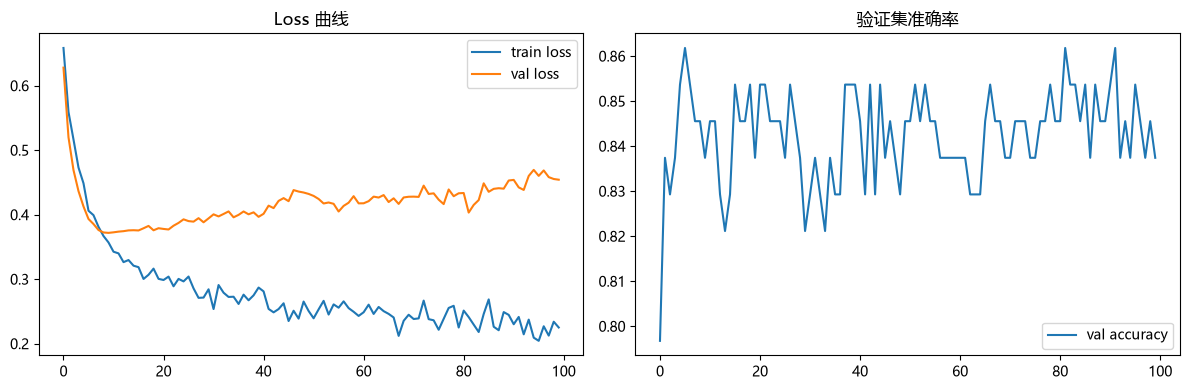


训练曲线图已保存。


In [10]:
# ============================================
# 8. 训练过程可视化：损失曲线与验证准确率曲线（任务流程第5步）
# ============================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(train_losses, label="train loss")
axes[0].plot(val_losses, label="val loss")
axes[0].set_title("Loss 曲线")
axes[0].legend()

axes[1].plot(val_accs, label="val accuracy")
axes[1].set_title("验证集准确率")
axes[1].legend()

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches='tight')
plt.show()
print("\n训练曲线图已保存。")



=== 验证集分类报告 ===
验证集 Accuracy: 0.8374
              precision    recall  f1-score   support

     0(无心脏病)       0.84      0.78      0.81        55
     1(有心脏病)       0.83      0.88      0.86        68

    accuracy                           0.84       123
   macro avg       0.84      0.83      0.83       123
weighted avg       0.84      0.84      0.84       123



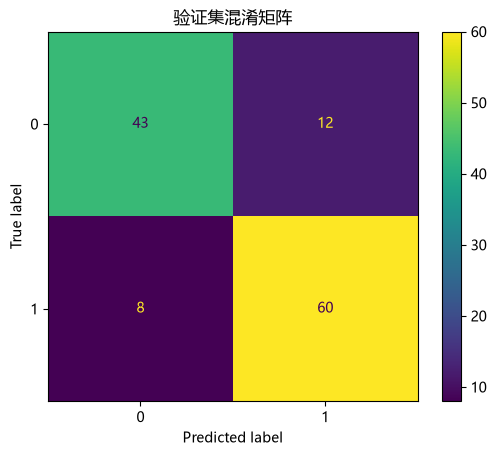

In [11]:
# ============================================
# 9. 评估：验证集混淆矩阵与分类指标（任务流程第5步）
# ============================================
model.eval()
with torch.no_grad():
    y_val_logits = model(torch.tensor(X_val, dtype=torch.float32))
    y_val_pred = (y_val_logits > 0).squeeze().numpy().astype(int)   # squeeze：把 (n,1) 压成 (n,)，否则 sklearn 指标/混淆矩阵会报错

print("\n=== 验证集分类报告 ===")
print(f"验证集 Accuracy: {accuracy_score(y_val, y_val_pred):.4f}")
print(classification_report(y_val, y_val_pred, target_names=["0(无心脏病)", "1(有心脏病)"]))

ConfusionMatrixDisplay(confusion_matrix(y_val, y_val_pred)).plot()
plt.title("验证集混淆矩阵")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches='tight')
plt.show()


In [12]:
# ============================================
# 10. 测试集预测 + 生成提交文件（任务流程第6步，对照 example_submission 格式）
# ============================================
model.eval()
with torch.no_grad():
    test_logits = model(torch.tensor(X_test, dtype=torch.float32))
    test_pred = (test_logits > 0).squeeze().numpy().astype(int)    # squeeze：保证提交文件是 1 维列（100,），否则 pandas 会报 Data must be 1-dimensional

submission = pd.DataFrame({"id": test["id"], "HeartDisease": test_pred})
print("\n=== 提交文件预览 ===")
print(submission.head())
print(f"提交文件行数: {len(submission)}")

# 保存提交文件
submission.to_csv("submission.csv", index=False)
print("\n已保存 submission.csv")
print(f"列名: {list(submission.columns)}（应为 ['id', 'HeartDisease']）")
print(f"行数: {len(submission)}（应与 test.csv 一致: {len(test)}）")



=== 提交文件预览 ===
    id  HeartDisease
0  669             0
1   31             1
2  378             1
3  536             1
4  808             0
提交文件行数: 100

已保存 submission.csv
列名: ['id', 'HeartDisease']（应为 ['id', 'HeartDisease']）
行数: 100（应与 test.csv 一致: 100）


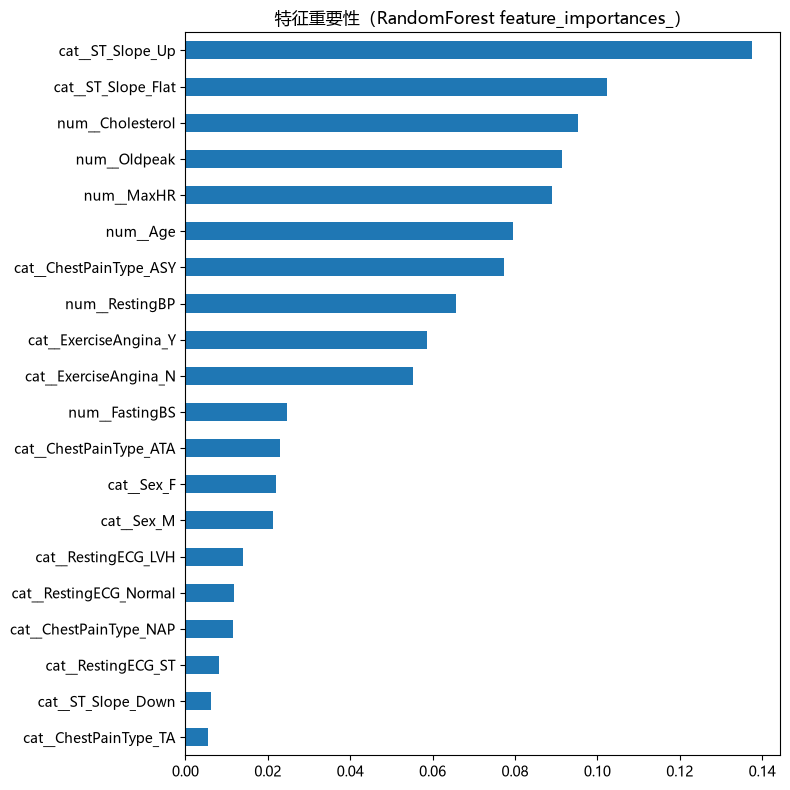


特征重要性图已保存。

=== 特征重要性排序（降序） ===
cat__ST_Slope_Up          0.137464
cat__ST_Slope_Flat        0.102239
num__Cholesterol          0.095264
num__Oldpeak              0.091471
num__MaxHR                0.089067
num__Age                  0.079613
cat__ChestPainType_ASY    0.077222
num__RestingBP            0.065771
cat__ExerciseAngina_Y     0.058535
cat__ExerciseAngina_N     0.055132
num__FastingBS            0.024700
cat__ChestPainType_ATA    0.023040
cat__Sex_F                0.021969
cat__Sex_M                0.021337
cat__RestingECG_LVH       0.013971
cat__RestingECG_Normal    0.011826
cat__ChestPainType_NAP    0.011481
cat__RestingECG_ST        0.008111
cat__ST_Slope_Down        0.006313
cat__ChestPainType_TA     0.005475


In [13]:
# ============================================
# 11. 特征重要性分析（对应思考题3）
# ============================================
# 用随机森林的 feature_importances_ 做定量评估
rf = RandomForestClassifier(n_estimators=300, random_state=42)
rf.fit(X, y)  # 在整个训练集上拟合，得到各特征的重要性

feat_names_array = preprocessor.get_feature_names_out()
imp = pd.Series(rf.feature_importances_, index=feat_names_array).sort_values(ascending=True)

plt.figure(figsize=(8, 8))
imp.plot(kind="barh")
plt.title("特征重要性（RandomForest feature_importances_）")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150, bbox_inches='tight')
plt.show()
print("\n特征重要性图已保存。")

# 打印排序结果
print("\n=== 特征重要性排序（降序） ===")
print(imp.sort_values(ascending=False).to_string())
